In [1]:
import os
import glob as gb
import json
import re
import numpy as np
import pandas as pd
import cv2
from collections import deque

import sys

sys.path.append("..")

import torch
import utils
from dataloader import preprocess_sal_img
import warnings

warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
from tqdm import tqdm
import random

In [2]:
def atoi(text):
    return int(text) if text.isdigit() else text


def natural_keys(text):
    return [atoi(c) for c in re.split(r"(\d+)", text)]

dataset_path = '../../processed_dataset/eht_dataset_prossesed_vid'
test_parent_folder = (
        os.path.join(dataset_path,"Video_8","User_8_Task_1"),
        # os.path.join(dataset_path,"Video_1","User_9_Task_1")
    )

json_paths_videos = []
for test_path in test_parent_folder:
    json_paths = gb.glob(os.path.join(test_path, "*.json"))
    json_paths.sort(key=natural_keys)
    json_paths_videos.append(json_paths)

raw_video_paths = gb.glob("/mnt/DataLake/AlienBackup/access/eht_dataset/Videos/*.mp4")


raw_video_path = []
metadata_videos = []
for json_paths in tqdm(json_paths_videos):
    metadata = []
    for json_path in json_paths:
        with open(json_path, "r") as f:
            data = json.load(f)
            df = pd.DataFrame(data)
            # df["sal_frame_number"] = range(1, len(df) + 1)
            metadata.append(df)
    
    metadata = pd.concat(metadata, ignore_index=True)
    video_id = metadata.iloc[0]['video_id']
    raw_video_path.extend([path for path in raw_video_paths if f"Video {video_id}" in path])
    metadata_videos.append(metadata)

100%|██████████| 1/1 [00:00<00:00, 12.42it/s]


In [4]:

# Load the model
trained_model_folder = 'trained_models_combined'
model_base_name = 'conv_tsmixer_past_timepoints_15_future_timepoints_6_sliding_window_8_20241122_175024'
model_epoch_name_path = 'model_epoch_9_val_loss_0.0002.pth'
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
time_model, timepoints, future_steps = utils.load_time_model(trained_model_folder, model_base_name, model_epoch_name_path, device)

# Create a VideoWriter object
fourcc = cv2.VideoWriter_fourcc(*"mp4v")  # Specify the codec

sal_path ='../models/unisal.pth'
unisal_model = utils.load_unisal(sal_path, device)

save_video = True

preds = []
preds_giw_diff = []
ground_truth = []
gt_giw_diff = []
all_previous_giw = []
all_previous_hmd = []
# Initliaze raw video capture
for idx_video, raw_video in enumerate(raw_video_path):
    print(raw_video)
    metadata = metadata_videos[idx_video]
    os.makedirs(f"../../results_combined_models/{model_base_name}", exist_ok=True)
    if save_video:
        output_video = cv2.VideoWriter(
        f"../../results_combined_models/{model_base_name}/pred6_{metadata.iloc[0]['video_id']}_{metadata.iloc[0]['user_id']}_{metadata.iloc[0]['task_id']}.mp4",
        fourcc,
        30.0,
        (1280, 720),
        )
    cap = cv2.VideoCapture(raw_video)
    if not cap.isOpened():
        raise ValueError("Error: Could not open video.")
    
    sal_frames = []
    # Create salency maps for timepoints-1 frames and save to sal_frames list
    for i in tqdm(range(timepoints-1)):
        fnumber = metadata.iloc[i]["frame_number"]
        cap.set(cv2.CAP_PROP_POS_FRAMES, fnumber)
        frame = cap.read()[1]
        if frame is None:
            continue
        frame_tensor = torch.tensor(np.array([preprocess_sal_img(frame)]), dtype=torch.float32)
        with torch.no_grad():
            sal_frame = unisal_model(frame_tensor.unsqueeze(0).to(device))
        sal_frames.append(sal_frame.squeeze().squeeze())

    for i in tqdm(range(timepoints-1, len(metadata) - future_steps)):
        # Get the last {current} frame
        fnumber = metadata.iloc[i]["frame_number"]
        cap.set(cv2.CAP_PROP_POS_FRAMES, fnumber)
        original_frame = cap.read()[1]
        if original_frame is None:
            continue
        frame = preprocess_sal_img(original_frame)
        
        frame_tensor = torch.tensor(np.array([frame]), dtype=torch.float32)
        # Load timepoint metadata
        meta_timepoints = metadata.iloc[i-timepoints+1: i+1]
        current_frame_data = meta_timepoints.iloc[-1]

        hmd_ang_vel_long = utils.calculate_angular_velocity(
            meta_timepoints["horz_hmd_deg"].to_numpy()
        )
        hmd_ang_vel_lat = utils.calculate_angular_velocity(
            meta_timepoints["vert_hmd_deg"].to_numpy()
        )
        hmd_ang_diff_long = utils.calculate_angle_diff(meta_timepoints["horz_hmd_deg"].to_numpy())
        hmd_ang_diff_lat = utils.calculate_angle_diff(meta_timepoints["vert_hmd_deg"].to_numpy())
        # Load current gaze and future gaze
        future_metadata_timepoints = metadata.iloc[i+1 : i+1+future_steps]
        giw_angdiff_long = (
            future_metadata_timepoints["giw_long"]
            - current_frame_data["horz_hmd_deg"]
        ) / 360
        giw_angdiff_lat = (
            future_metadata_timepoints["giw_lat"]
            - current_frame_data["vert_hmd_deg"]
        ) / 180

        # Load saliency maps
        with torch.no_grad():
            sal_frame = unisal_model(frame_tensor.unsqueeze(0).to(device))

        sal_frames.append(sal_frame.squeeze().squeeze())
        if len(sal_frames)>timepoints:
            sal_frames.pop(0)
        # Normalize frames to the range [-1, 1]
        sal_frames_processed = utils.sal_process(torch.stack(sal_frames, dim=0).cpu().detach()).squeeze()
        sal_frames_processed = sal_frames_processed.to(device)
        
        # # Keep frames with iterval ex. sal video at 6fps and timepoints at 30fps
        # sal_frame_idx = metadata.iloc[i]["sal_frame_number"]
        # sal_idxs = sorted([sal_frame_idx - k * interval for k in range(sal_frames_keep)])
        # for idx in sal_idxs:
        #     sal_cap.set(cv2.CAP_PROP_POS_FRAMES, idx - 1)
        #     ret, sal_frame = sal_cap.read()
        #     if not ret:
        #         break
        #     # print(len(sal_frames))
        #     sal_frames.append(cv2.cvtColor(sal_frame, cv2.COLOR_BGR2GRAY))
        # if len(sal_frames) != sal_frames_keep:
        #     pass
        
        timeseries = list(
            zip(hmd_ang_vel_long, hmd_ang_vel_lat, hmd_ang_diff_long, hmd_ang_diff_lat)
        )

        pred = time_model(
            torch.tensor(sal_frames_processed, dtype=torch.float32).unsqueeze(0).to(device),
            torch.tensor(timeseries, dtype=torch.float32).unsqueeze(0).to(device),
        )
        
        pred_np = pred[0].detach().cpu().numpy()
        # Visualize prediction
        p_long = pred_np[:, 0] * 360 + current_frame_data["horz_hmd_deg"]
        p_lat = pred_np[:, 1] * 180 + current_frame_data["vert_hmd_deg"]
        preds.append([p_long, p_lat])
        preds_giw_diff.append([pred_np[:,0], pred_np[:, 1]])

        g_long = future_metadata_timepoints["giw_long"].to_numpy()
        g_lat = future_metadata_timepoints["giw_lat"].to_numpy()
        ground_truth.append([g_long, g_lat])
        gt_giw_diff.append([giw_angdiff_long, giw_angdiff_lat])
        
        previous_future_metadata = metadata.iloc[i-timepoints+1: i+1+future_steps]
        # input degrees
        i_long = previous_future_metadata["giw_long"].to_numpy()
        i_lat = previous_future_metadata["giw_lat"].to_numpy()
        all_previous_giw.append([i_long, i_lat])
        
        i_long = previous_future_metadata["horz_hmd_deg"].to_numpy()
        i_lat = previous_future_metadata["vert_hmd_deg"].to_numpy()
        all_previous_hmd.append([i_long, i_lat])
        # Visualize frame
        # Video dimensions
        width, height = original_frame.shape[1], original_frame.shape[0]
        fov_bottom, fov_top, fov_left, fov_right = current_frame_data[
            ["fov_bottom", "fov_top", "fov_left", "fov_right"]
        ].values
        if save_video:
            # Draw FOV
            vis_frame = utils.draw_fov_frame(
                original_frame, fov_top, fov_bottom, fov_left, fov_right, width, height
            )
            if vis_frame is None:
                pass
            
            # Draw gaze circles ground truth and prediction # Green True, Red Prediction
            vis_frame = utils.draw_gaze(
                vis_frame, g_long[5], g_lat[5], width, height, color=(0, 255, 0)
            )
            vis_frame = utils.draw_gaze(
                vis_frame, p_long[5], p_lat[5], width, height, color=(0, 0, 255)
            )
            vis_frame = cv2.resize(vis_frame, (1280, 720))
            
            # Save the current frame to the video file
            if vis_frame is not None:
                output_video.write(vis_frame)
    cap.release()
    if save_video:
        output_video.release()

/mnt/DataLake/AlienBackup/access/eht_dataset/Videos/Video 8 - LOSC Football.mp4


100%|██████████| 4330/4330 [17:32<00:00,  4.12it/s]


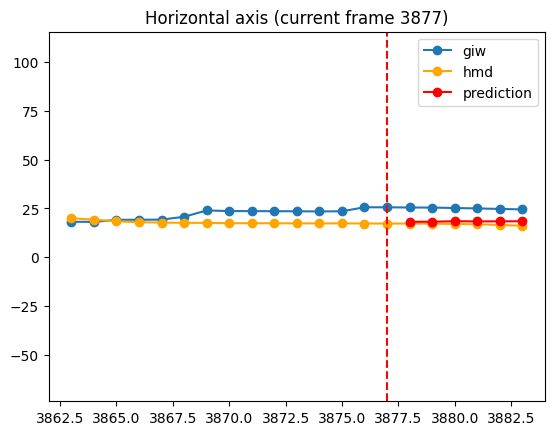

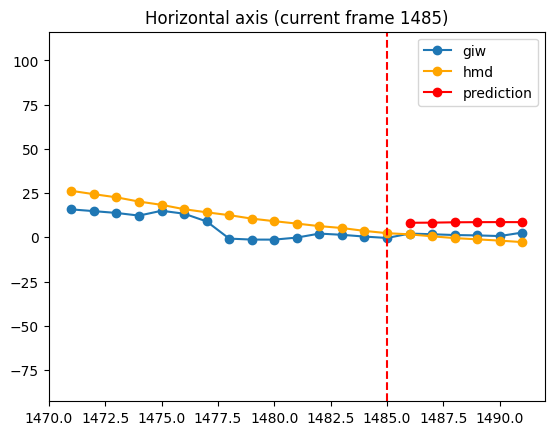

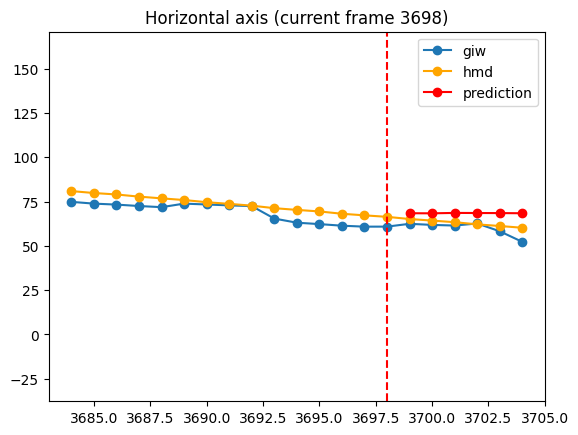

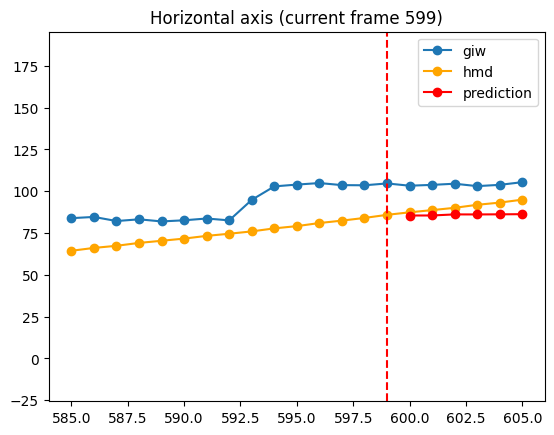

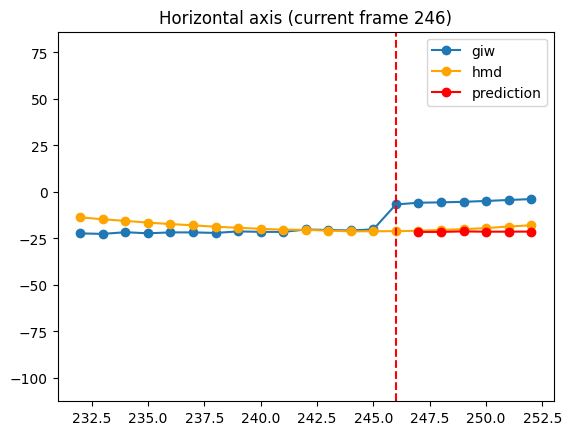

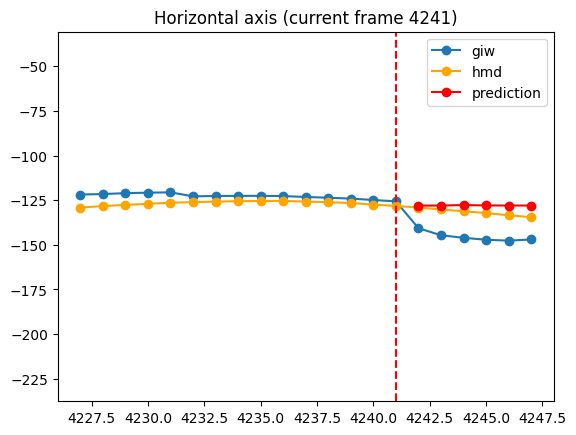

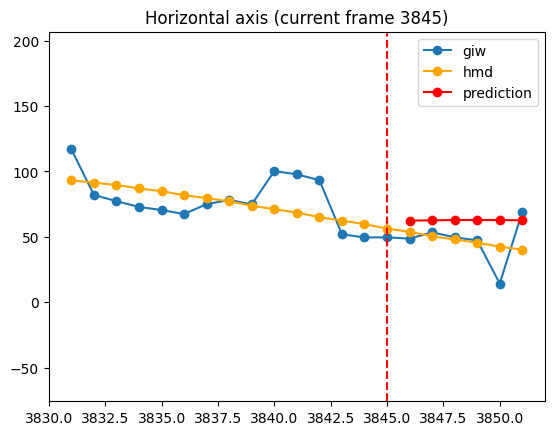

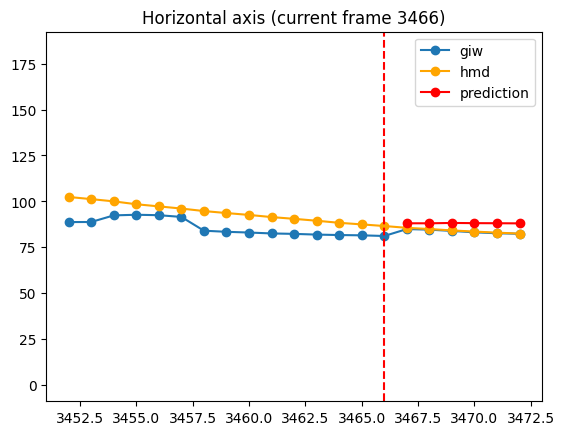

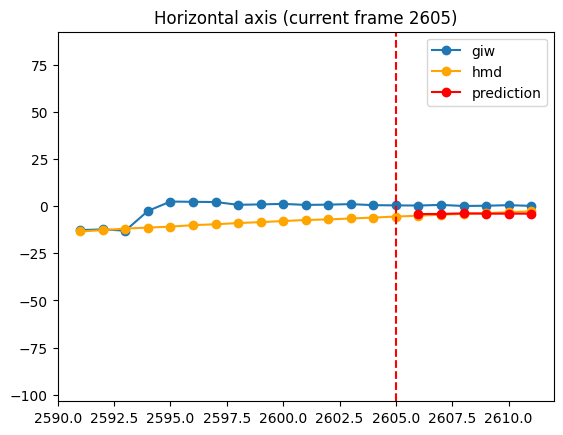

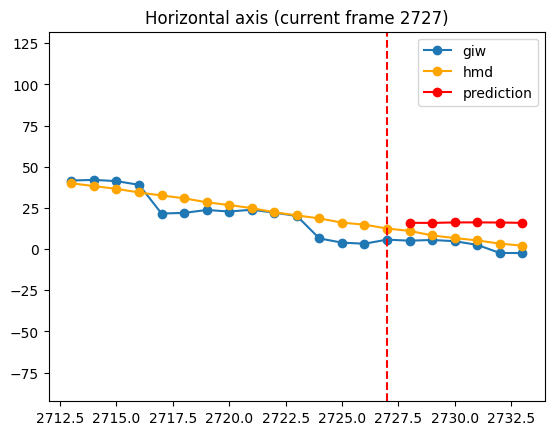

In [10]:
for i in random.sample(range(0, len(preds)), 10):
    plt.figure()
    plt.plot(range(i+1, i+1+timepoints+future_steps), all_previous_giw[i][0], '-o', label='giw')
    plt.plot(range(i+1, i+1+timepoints+future_steps), all_previous_hmd[i][0], '-o', label='hmd', color='orange')
    plt.plot(range(i+timepoints+1, i+1+timepoints+future_steps), preds[i][0], '-o', color='r', label='prediction')
    plt.axvline(x = i+timepoints, color = 'r', linestyle = '--') 
    plt.title(f'Horizontal axis (current frame {i+timepoints})')
    plt.legend()
    mini = min(min(all_previous_giw[i][0]), min(all_previous_hmd[i][0]), min(preds[i][0]))
    maxi = max(max(all_previous_giw[i][0]), max(all_previous_hmd[i][0]), max(preds[i][0]))
    plt.ylim(mini - max((90 - (maxi - mini)/2), 90), maxi + max((90 - (maxi - mini)/2), 90))
    plt.show()


In [11]:
# for j in random.sample(range(4331, len(preds)), 10):
#     i = j-4330
#     plt.figure()
#     plt.plot(range(i+1, i+1+timepoints+future_steps), all_previous_giw[j][0], '-o', label='giw')
#     plt.plot(range(i+1, i+1+timepoints+future_steps), all_previous_hmd[j][0], '-o', label='hmd', color='orange')
#     plt.plot(range(i+timepoints+1, i+1+timepoints+future_steps), preds[j][0], '-o', color='r', label='prediction')
#     plt.axvline(x = i+timepoints, color = 'r', linestyle = '--') 
#     plt.title(f'Horizontal axis (current frame {i+timepoints})')
#     plt.legend()
#     mini = min(min(all_previous_giw[j][0]), min(all_previous_hmd[j][0]), min(preds[j][0]))
#     maxi = max(max(all_previous_giw[j][0]), max(all_previous_hmd[j][0]), max(preds[j][0]))
#     plt.ylim(mini - max((90 - (maxi - mini)/2), 90), maxi + max((90 - (maxi - mini)/2), 90))
#     plt.show()

In [12]:
np.array(preds).shape

(4330, 2, 6)

In [13]:
np.sqrt(np.mean(
    (np.array(preds_giw_diff)[:, 0, :] - np.array(gt_giw_diff)[:, 0, :])**2,
    axis=0,
))

array([0.15385522, 0.15750102, 0.16095065, 0.16541408, 0.16971076,
       0.17379763])

In [14]:
np.sqrt(np.mean(
    (np.array(preds)[:, 0, :] - np.array(ground_truth)[:, 0, :])**2,
    axis=0,
))

array([55.38788012, 56.70036648, 57.94223548, 59.54906712, 61.09587257,
       62.56714531])

In [15]:
np.sqrt(np.mean((np.array(preds)[:, 1, :] - np.array(ground_truth)[:, 1, :])**2, axis=0))

array([6.57361621, 6.60229248, 6.62894549, 6.6873035 , 6.73294516,
       6.76654356])

In [ ]:
(
    pred[0][0][[1, 3]].detach().cpu().numpy() * 180
    + future_metadata_timepoints["vert_hmd_deg"].to_numpy()
)

In [ ]:
(
    giw_angdiff_long.to_numpy() * 360
    + future_metadata_timepoints["horz_hmd_deg"].to_numpy()
)

In [ ]:
timeseries = list(
    zip(hmd_ang_vel_long, hmd_ang_vel_lat, hmd_ang_diff_long, hmd_ang_diff_lat)
)
model(
    torch.tensor(sal_frames, dtype=torch.float32).unsqueeze(0).to("cuda"),
    torch.tensor(timeseries, dtype=torch.float32).unsqueeze(0).to("cuda"),
)

In [ ]:
meta_timepoints["horz_hmd_deg"].to_numpy()

In [ ]:
import matplotlib.pyplot as plt

plt.imshow(frame)
plt.show()